<a href="https://colab.research.google.com/github/hoangmaituanhiep/DangerZoneDetection/blob/main/notebooks/colab_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi
import torch
import tensorflow as tf
from google.colab import drive
drive.mount("/content/drive")

Sat Nov 14 02:59:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os

DRIVE_ROOT = "/content/drive/MyDrive/DangerZoneDetection"
DATA_ZIP   = f"{DRIVE_ROOT}/data/FER2013.zip"
RUNS_DIR   = f"{DRIVE_ROOT}/runs"
MODELS_DIR = f"{DRIVE_ROOT}/models"
LOCAL_DATA = "/content/fer_plus"   # nơi giải nén (ổ cục bộ của Colab, đọc nhanh)

for d in (RUNS_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

assert os.path.exists(DATA_ZIP), f"Không tìm thấy {DATA_ZIP}. Kiểm tra lại đã upload zip lên Drive chưa."

In [3]:
REPO     = "https://github.com/hoangmaituanhiep/DangerZoneDetection.git"
REPO_DIR = "/content/DangerZoneDetection"

if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO} {REPO_DIR}

%cd {REPO_DIR}

if not os.path.exists(LOCAL_DATA):
    !cp "{DATA_ZIP}" /content/FER2013.zip
    !unzip -q /content/FER2013.zip -d {LOCAL_DATA}
else:
    !rm -rf /content/fer_plus/
    !cp "{DATA_ZIP}" /content/FER2013.zip
    !unzip -q /content/FER2013.zip -d {LOCAL_DATA}

!ls {LOCAL_DATA}

Cloning into '/content/DangerZoneDetection'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (32/32), done.
remote: Total 48 (delta 14), reused 22 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 139.54 KiB | 1.20 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/DangerZoneDetection
FER2013Test  FER2013Train  FER2013Valid


In [4]:
import glob
import pandas as pd

train_dirs = glob.glob(f"{LOCAL_DATA}/**/FER2013Train", recursive=True)
assert train_dirs, "Không thấy thư mục FER2013Train trong dữ liệu đã giải nén."
BASE = os.path.dirname(train_dirs[0])
print("Thư mục gốc dữ liệu:", BASE)

SPLITS = {"train": "FER2013Train", "val": "FER2013Valid", "test": "FER2013Test"}
EMOTIONS = ["neutral", "happiness", "surprise", "sadness", "anger", "disgust", "fear", "contempt"]
VOTE_COLS = EMOTIONS + ["unknown", "NF"]

def load_split(folder):
    # label.csv: tên ảnh, khung mặt, rồi 10 cột số phiếu (không có dòng tiêu đề)
    df = pd.read_csv(f"{BASE}/{folder}/label.csv", header=None)
    df.columns = ["image", "box"] + VOTE_COLS
    votes = df[VOTE_COLS].values
    top = votes.argmax(axis=1)
    df["label_id"] = top
    df = df[df["label_id"] < len(EMOTIONS)].copy()          # bỏ unknown / NF
    df["label"] = df["label_id"].map(lambda i: EMOTIONS[i])
    df["path"] = f"{BASE}/{folder}/" + df["image"]
    return df.reset_index(drop=True)

dfs = {name: load_split(folder) for name, folder in SPLITS.items()}

for name, df in dfs.items():
    print(f"\n== {name}: {len(df)} ảnh ==")
    print(df["label"].value_counts().to_string())

# kiểm tra file ảnh có thật
missing = [p for p in dfs["train"]["path"].head(200) if not os.path.exists(p)]
print("\nẢnh bị thiếu (trong 200 ảnh đầu của train):", len(missing))

Thư mục gốc dữ liệu: /content/fer_plus

== train: 28385 ảnh ==
label
neutral      10295
happiness     7526
surprise      3557
sadness       3530
anger         2463
fear           655
disgust        191
contempt       168

== val: 3555 ảnh ==
label
neutral      1329
happiness     899
surprise      458
sadness       415
anger         325
fear           71
disgust        32
contempt       26

== test: 3545 ảnh ==
label
neutral      1258
happiness     928
surprise      447
sadness       446
anger         321
fear           97
contempt       28
disgust        20

Ảnh bị thiếu (trong 200 ảnh đầu của train): 0


In [ ]:
train = pd.DataFrame(dfs['train'])
val = pd.DataFrame(dfs['val'])
test = pd.DataFrame(dfs['test'])
print(train['image'])
print(train['label'])
print(pd.unique(train['label']))

0        fer0000000.png
1        fer0000001.png
2        fer0000002.png
3        fer0000003.png
4        fer0000004.png
              ...      
28380    fer0028633.png
28381    fer0028634.png
28382    fer0028635.png
28383    fer0028636.png
28384    fer0028637.png
Name: image, Length: 28385, dtype: object
0        neutral
1        neutral
2        neutral
3        neutral
4        neutral
          ...   
28380       fear
28381      anger
28382    sadness
28383    neutral
28384    neutral
Name: label, Length: 28385, dtype: object
['neutral' 'sadness' 'happiness' 'surprise' 'anger' 'fear' 'contempt'
 'disgust']


In [ ]:
print(pd.unique(train['label']))

['neutral' 'sadness' 'happiness' 'surprise' 'anger' 'fear' 'contempt'
 'disgust']


In [5]:
import matplotlib.pyplot as plt
def plot_learning_curve(history, model_name="Model"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    epochs = range(1, len(history.history['loss']) + 1)

    # --- Loss ---
    ax1.plot(epochs, history.history['loss'],     label='Train Loss')
    ax1.plot(epochs, history.history['val_loss'], label='Val Loss')
    ax1.set_title(f'{model_name} — Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()

    # --- Accuracy ---
    ax2.plot(epochs, history.history['accuracy'],     label='Train Accuracy')
    ax2.plot(epochs, history.history['val_accuracy'], label='Val Accuracy')
    ax2.set_title(f'{model_name} — Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
train['label'] = le.fit_transform(train['label'])
val['label'] = le.transform(val['label'])
test['label'] = le.transform(test['label'])
res = test['label'].values
test = test.drop(columns=['label'])

In [6]:
IMG_SIZE = 48
BATCH = 128
NUM_CLASSES = len(EMOTIONS)
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(df, training, img_size=96, batch=64):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label_id"].values.astype("int32")))
    def load(path, y):
        img = tf.io.read_file(path)
        img = tf.image.decode_png(img, channels=3)          # xám -> 3 kênh
        img = tf.image.resize(img, (img_size, img_size), method="bicubic")
        img = tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8)
        return img, y
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=42)
    return ds.batch(batch).prefetch(AUTOTUNE)

train_ds = make_ds(dfs["train"], training=True)
val_ds   = make_ds(dfs["val"],   training=False)
test_ds  = make_ds(dfs["test"],  training=False)

In [7]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = dfs['train']['label_id'].values
counts = np.bincount(y_train)
w = (counts.sum()/counts)**0.5
w = np.clip(w/w.mean(), 0.3, 3.0)
weights = dict(enumerate(w))

In [ ]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.5),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
], name='augment')

def build_baseline():
  inputs = tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 1))
  x = tf.keras.layers.Rescaling(1/255.0) (inputs)
  x = augment(x)
  for f, drop in ((32, 0.1), (64, 0.1), (128, 0.2), (256, 0.2)):
    for _ in range(2):
      x = tf.keras.layers.Conv2D(f, 3, padding='same', activation='relu') (x)
      x = tf.keras.layers.BatchNormalization() (x)
      x = tf.keras.layers.ReLU() (x)
    x = tf.keras.layers.MaxPooling2D() (x)
    x = tf.keras.layers.Dropout(drop) (x)
  x = tf.keras.layers.GlobalAveragePooling2D() (x)
  x = tf.keras.layers.Dense(256, activation='relu') (x)
  x = tf.keras.layers.Dropout(0.3) (x)
  outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax') (x)
  return tf.keras.Model(inputs, outputs, name='baseline')

model = build_baseline()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_11 (ReLU)                 │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_12 (ReLU)                 │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,243,368 (4.74 MB)

 Trainable params: 1,241,448 (4.74 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/60
222/222 - 26s - 117ms/step - accuracy: 0.3195 - loss: 0.8432 - val_accuracy: 0.3738 - val_loss: 2.0249 - learning_rate: 0.0010
Epoch 2/60
222/222 - 16s - 72ms/step - accuracy: 0.3468 - loss: 0.8159 - val_accuracy: 0.3716 - val_loss: 1.8158 - learning_rate: 0.0010
Epoch 3/60
222/222 - 20s - 91ms/step - accuracy: 0.3718 - loss: 0.8018 - val_accuracy: 0.4079 - val_loss: 1.6064 - learning_rate: 0.0010
Epoch 4/60
222/222 - 15s - 69ms/step - accuracy: 0.3990 - loss: 0.7736 - val_accuracy: 0.3879 - val_loss: 1.6146 - learning_rate: 0.0010
Epoch 5/60
222/222 - 15s - 69ms/step - accuracy: 0.4255 - loss: 0.7427 - val_accuracy: 0.2985 - val_loss: 2.0372 - learning_rate: 0.0010
Epoch 6/60
222/222 - 16s - 70ms/step - accuracy: 0.4569 - loss: 0.7199 - val_accuracy: 0.4487 - val_loss: 1.5565 - learning_rate: 0.0010
Epoch 7/60
222/222 - 16s - 71ms/step - accuracy: 0.5153 - loss: 0.6837 - val_accuracy: 0.5297 - val_loss: 1.3528 - learning_rate: 0.0010
Epoch 8/60
222/222 - 16s - 72ms/step - a

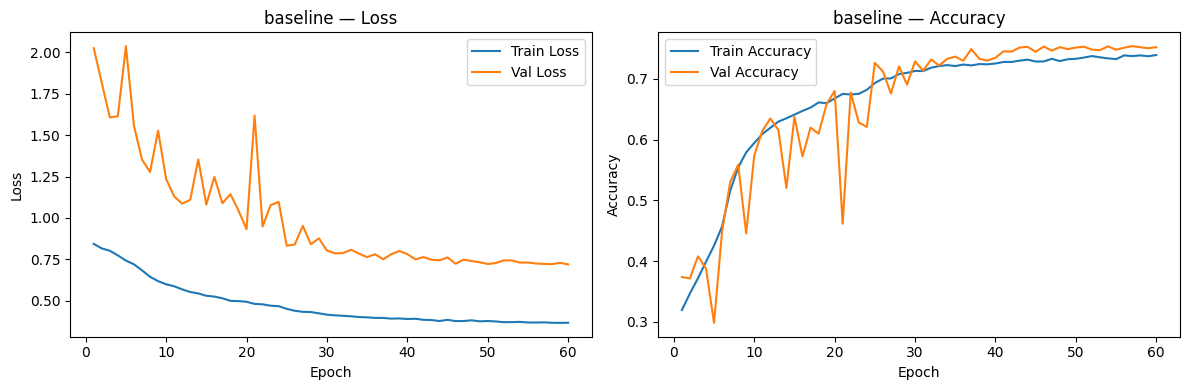

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7306 - loss: 0.7627


In [ ]:
run_name = 'baseline'
os.makedirs(f"{RUNS_DIR}/{run_name}", exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(f'{RUNS_DIR}/{run_name}/best.keras', monitor='val_accuracy', mode = 'max', save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=4, verbose=0, min_lr=1e-5),
    tf.keras.callbacks.TensorBoard(f'{RUNS_DIR}/{run_name}')
]

his = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=callbacks, class_weight=weights, verbose=2)
plot_learning_curve(his, model_name=run_name)
loss, acc = model.evaluate(test_ds)

In [8]:
BACKBONES = {
    "efficientnetb0": (tf.keras.applications.EfficientNetB0, None),   # nhận 0-255
    "mobilenetv2": (tf.keras.applications.MobileNetV2,
                    tf.keras.applications.mobilenet_v2.preprocess_input),
    "resnet50v2": (tf.keras.applications.ResNet50V2,
                   tf.keras.applications.resnet_v2.preprocess_input),
}

def make_augment(s):
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(s),
        tf.keras.layers.RandomTranslation(s, s),
    ])

def build_transfer(name, img_size, dropout=0.3, aug=0.05):
    Backbone, prep = BACKBONES[name]
    base = Backbone(include_top=False, weights="imagenet",
                    input_shape=(img_size, img_size, 3))
    base.trainable = False
    inp = tf.keras.Input((img_size, img_size, 3), dtype="uint8")
    x = tf.keras.layers.Rescaling(1.0)(inp)                 # ép sang float, giữ thang 0-255
    x = make_augment(aug)(x)
    if prep is not None:
        x = tf.keras.layers.Lambda(prep)(x)
    x = base(x, training=False)                             # BN ở chế độ inference
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inp, out), base

def compile_model(model, lr, wd=1e-4):
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"])

In [11]:
from sklearn.metrics import f1_score

def val_macro_f1(model, ds, y_true):
    return f1_score(y_true, model.predict(ds, verbose=0).argmax(1), average="macro")

train_ds = make_ds(dfs["train"], True,  img_size=96)
val_ds   = make_ds(dfs["val"],   False, img_size=96)

In [ ]:
run_name = "transfer-efficientnetb0"
os.makedirs(f"{RUNS_DIR}/{run_name}", exist_ok=True)
model, base = build_transfer("efficientnetb0", 96)

# Giai đoạn A: chỉ train head
compile_model(model, lr=1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=weights, verbose=0)

# Giai đoạn B: mở khóa backbone, lr nhỏ hơn 10 lần
base.trainable = True
for l in base.layers:
    if isinstance(l, tf.keras.layers.BatchNormalization):
        l.trainable = False
compile_model(model, lr=1e-4)                               # bắt buộc compile lại
cbs = [tf.keras.callbacks.ModelCheckpoint(f'{RUNS_DIR}/{run_name}/best.keras', monitor='val_accuracy', mode = 'max', save_best_only=True),
       tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
       tf.keras.callbacks.TensorBoard(f'{RUNS_DIR}/{run_name}')]
model.fit(train_ds, validation_data=val_ds, epochs=40, class_weight=weights, callbacks=cbs, verbose=0)
print("Val macro-F1:", val_macro_f1(model, val_ds, dfs["val"]["label_id"].values))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Val macro-F1: 0.6719954992279673


In [ ]:
run_name = "transfer-resnet50v2"
os.makedirs(f"{RUNS_DIR}/{run_name}", exist_ok=True)
model, base = build_transfer("resnet50v2", 96)

# Giai đoạn A: chỉ train head
compile_model(model, lr=1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=weights, verbose=0)

# Giai đoạn B: mở khóa backbone, lr nhỏ hơn 10 lần
base.trainable = True
for l in base.layers:
    if isinstance(l, tf.keras.layers.BatchNormalization):
        l.trainable = False
compile_model(model, lr=1e-4)                               # bắt buộc compile lại
cbs = [tf.keras.callbacks.ModelCheckpoint(f'{RUNS_DIR}/{run_name}/best.keras', monitor='val_accuracy', mode = 'max', save_best_only=True),
       tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
       tf.keras.callbacks.TensorBoard(f'{RUNS_DIR}/{run_name}')]
model.fit(train_ds, validation_data=val_ds, epochs=40, class_weight=weights, callbacks=cbs, verbose=0)
print("Val macro-F1:", val_macro_f1(model, val_ds, dfs["val"]["label_id"].values))

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Val macro-F1: 0.6581871343006956


In [ ]:
run_name = "transfer-mobilenetv2"
os.makedirs(f"{RUNS_DIR}/{run_name}", exist_ok=True)
model, base = build_transfer("mobilenetv2", 96)

# Giai đoạn A: chỉ train head
compile_model(model, lr=1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=weights, verbose=0)

# Giai đoạn B: mở khóa backbone, lr nhỏ hơn 10 lần
base.trainable = True
for l in base.layers:
    if isinstance(l, tf.keras.layers.BatchNormalization):
        l.trainable = False
compile_model(model, lr=1e-4)                               # bắt buộc compile lại
cbs = [tf.keras.callbacks.ModelCheckpoint(f'{RUNS_DIR}/{run_name}/best.keras', monitor='val_accuracy', mode = 'max', save_best_only=True),
       tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
       tf.keras.callbacks.TensorBoard(f'{RUNS_DIR}/{run_name}')]
model.fit(train_ds, validation_data=val_ds, epochs=40, class_weight=weights, callbacks=cbs, verbose=0)
print("Val macro-F1:", val_macro_f1(model, val_ds, dfs["val"]["label_id"].values))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Val macro-F1: 0.7056414702026846


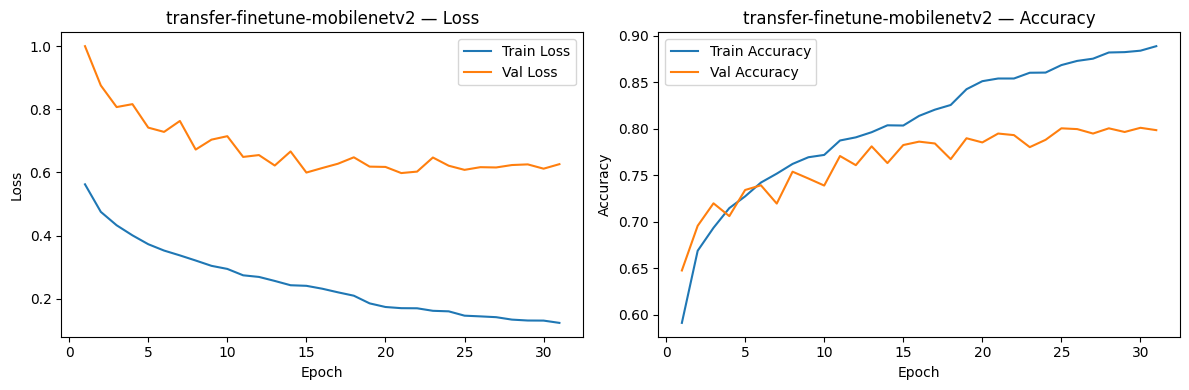

Val macro-F1: 0.6637311150991159


In [12]:
run_name = "transfer-finetune-mobilenetv2"
os.makedirs(f"{RUNS_DIR}/{run_name}", exist_ok=True)
model, base = build_transfer("mobilenetv2", 96)

compile_model(model, lr=1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=weights, verbose=0)
base.trainable = True
for l in base.layers:
    if isinstance(l, tf.keras.layers.BatchNormalization):
        l.trainable = False
compile_model(model, lr=3e-5)
cbs = [tf.keras.callbacks.ModelCheckpoint(f'{RUNS_DIR}/{run_name}/tune.keras', monitor='val_accuracy', mode = 'max', save_best_only=True),
       tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
       tf.keras.callbacks.TensorBoard(f'{RUNS_DIR}/{run_name}')]
his = model.fit(train_ds, validation_data=val_ds, epochs=60, class_weight=weights, callbacks=cbs, verbose=0)
plot_learning_curve(his, model_name=run_name)
print("Val macro-F1:", val_macro_f1(model, val_ds, dfs["val"]["label_id"].values))